Olá, Maria Clara

Meu nome é Ramon. Ao ao longo do texto farei algumas observações sobre melhorias no código. Nas partes em que não houver comentários, está tudo certo, ok? Estarei aberto a feedbacks e discussões sobre o tema.

**Peço que mantenha e não altere os comentários que eu fizer por aqui para que possamos nos localizar posteriormente, ok?**

Vamos utilizar este código de cores para você entender os meus feedbacks no seu notebook:

<div class="alert alert-block alert-success">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Alerta não crítco, mas que pode ser corrigido para melhoria geral no seu código/análise
</div>

<div class="alert alert-block alert-danger">

<b>Comentário do revisor: </b> <a class="tocSkip"></a>
    
Erro que precisa ser consertado, caso contrário seu projeto **não** será aceito.
</div>

Você pode me responder usando isso:
<div class="alert alert-block alert-info">
<b>Resposta do Aluno.</b> <a class="tocSkip"></a>
</div>

###

<div class="alert alert-block alert-success">
<b>Comentário Geral do Revisor</b> <a class="tocSkip"></a>

Obrigado por enviar seu projeto. 
    
Parabéns, você fez um bom trabalho.

Como pontos fortes do projeto, destaco:
- Código simples e eficiente (sem loop desnecessário)
- Uso adequado dos recursos da lição



Porém, há espaço para melhorias:
- ajustar teste de hipótese
- aplicar fillna(0)



Portanto, sugiro que você corrija os pontos indicados.
    
Se você tiver alguma dúvida sobre de algo que você não tenha entendido, sinta-se à vontade para perguntar ao tutor ou deixar um comentário em **azul** para que, na próxima iteração, eu possa responder.

Conte conosco. Lembre-se de que você pode tirar dúvidas com revisores usando os comentários ou buscar ajuda de um tutor.
Bom trabalho. 
</div>




<div class="alert alert-block alert-success">
<b> Comentário Geral do revisor: </b> <a class="tocSkip"></a>

Tudo certo agora. Parabéns pelo empenho. Desejo sucesso na jornada.

</div>

# Qual é o melhor plano?

Você trabalha como analista para a empresa de telecomunicações Megaline. A empresa oferece aos clientes dois planos pré-pagos: Surf e Ultimate. O departamento comercial quer saber qual dos planos gera mais receita para ajustar o orçamento de publicidade.

Você vai realizar uma análise preliminar dos planos com base em uma pequena seleção de clientes. Você terá dados de 500 clientes da Megaline: que clientes são, de onde eles são, qual plano usam e o número de chamadas e mensagens realizadas em 2018. Seu trabalho é analisar o comportamento dos clientes e determinar qual plano pré-pago gera mais receita.

[Fornecemos alguns comentários para guiar sua linha de raciocínio enquanto você trabalha neste projeto. Entretanto, certifique-se de remover todos os comentários entre colchetes antes de enviar o projeto.]

[Antes de começar a análise dos dados, explique com suas próprias palavras o propósito do projeto e as ações que planeja realizar.]

[Tenha em mente que estudar, modificar e analisar dados é um processo iterativo. É normal retornar a etapas anteriores e corrigir/expandir algo para permitir as próximas etapas.]

## Inicialização

In [1]:

# Carregando todas as bibliotecas

import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats as st
import matplotlib.pyplot as plt

## Carregue os dados

In [2]:

# Carregue os arquivos de dados em diferentes DataFrames

calls = pd.read_csv('/datasets/megaline_calls.csv')
internet = pd.read_csv('/datasets/megaline_internet.csv')
messages = pd.read_csv('/datasets/megaline_messages.csv')
plans = pd.read_csv('/datasets/megaline_plans.csv')
users = pd.read_csv('/datasets/megaline_users.csv')

## Prepare os dados

## Planos

In [3]:

# Imprima informações gerais/resumo sobre o DataFrame dos planos
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes


In [4]:

# Imprima uma amostra de dados dos planos
print(plans)

   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  
1               70           7             0.01            0.01  ultimate  



Os dados dos planos estão limpos e bem estruturados. Não foram identificados problemas como dados ausentes ou duplicados, espaços extra nos nomes, tipos inadequados ou inconsistências nos nomes. 
Os dois planos (surf e ultimate) estão claramente diferenciados com suas respectivas condições e preços.

## Corrija os dados

## Enriqueça os dados

In [5]:
# Convertendo MB para GB (dividindo por 1024)

plans['gb_per_month_included'] = plans['mb_per_month_included'] / 1024
plans['gb_per_month_included'] = plans['gb_per_month_included'].astype(int)
print(plans)

   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  \
0               20          10             0.03            0.03      surf   
1               70           7             0.01            0.01  ultimate   

   gb_per_month_included  
0                     15  
1                     30  


## Usuários

In [6]:
# Imprima informações gerais/resumo sobre o DataFrame dos usuários

users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


In [7]:
# Imprima uma amostra de dados dos usuários

print(users.head(10))
print(f"Duplicados em users: {users.duplicated().sum()}")

   user_id first_name  last_name  age                                    city  \
0     1000   Anamaria      Bauer   45   Atlanta-Sandy Springs-Roswell, GA MSA   
1     1001     Mickey  Wilkerson   28         Seattle-Tacoma-Bellevue, WA MSA   
2     1002     Carlee    Hoffman   36    Las Vegas-Henderson-Paradise, NV MSA   
3     1003   Reynaldo    Jenkins   52                           Tulsa, OK MSA   
4     1004    Leonila   Thompson   40         Seattle-Tacoma-Bellevue, WA MSA   
5     1005      Livia    Shields   31     Dallas-Fort Worth-Arlington, TX MSA   
6     1006     Jesusa   Bradford   73  San Francisco-Oakland-Berkeley, CA MSA   
7     1007    Eusebio      Welch   42           Grand Rapids-Kentwood, MI MSA   
8     1008      Emely    Hoffman   53       Orlando-Kissimmee-Sanford, FL MSA   
9     1009      Gerry     Little   19  San Jose-Sunnyvale-Santa Clara, CA MSA   

     reg_date      plan  churn_date  
0  2018-12-24  ultimate         NaN  
1  2018-08-13      surf         

[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]
Constatámos que não existem linhas duplicadas.
As colunas 'reg_date' e churn_date possuem dados de tipo 'object' e deveria ser de tipo 'datetime', pelo que será efetuada esta correção.
A coluna 'churn_date' possui 466 valores ausentes. Estes valores ausentes serão mantidos, pois indicam que o contrato ainda estava vigente no momento da extração dos dados.

Para enriquecer o DataFrame, criarei uma coluna booleana para identificar utilizadores da região 'NY-NJ' e extrairei o mês de registo, facilitando a análise de consumo mensal que faremos a seguir.

### Corrija os dados

In [8]:

users['reg_date'] = pd.to_datetime(users['reg_date'])
users['churn_date'] = pd.to_datetime(users['churn_date'])

### Enriqueça os dados

In [9]:

users['is_ny_nj'] = users['city'].str.contains('NY-NJ', case=False) # Criando a marcação para NY-NJ
users['reg_month'] = users['reg_date'].dt.month # Extraindo o mês de registro

users.info()
print(users.head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    object        
 2   last_name   500 non-null    object        
 3   age         500 non-null    int64         
 4   city        500 non-null    object        
 5   reg_date    500 non-null    datetime64[ns]
 6   plan        500 non-null    object        
 7   churn_date  34 non-null     datetime64[ns]
 8   is_ny_nj    500 non-null    bool          
 9   reg_month   500 non-null    int64         
dtypes: bool(1), datetime64[ns](2), int64(3), object(4)
memory usage: 35.8+ KB
   user_id first_name  last_name  age                                    city  \
0     1000   Anamaria      Bauer   45   Atlanta-Sandy Springs-Roswell, GA MSA   
1     1001     Mickey  Wilkerson   28         Seattle-Tacoma-Bellevue, WA MSA 

## Chamadas

In [10]:

# Imprima informações gerais/resumo sobre o DataFrame das chamadas
calls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB


In [11]:

# Imprima uma amostra de dados das chamadas
print(calls.head(10))
print(f"Duplicados em calls: {calls.duplicated().sum()}")


         id  user_id   call_date  duration
0   1000_93     1000  2018-12-27      8.52
1  1000_145     1000  2018-12-27     13.66
2  1000_247     1000  2018-12-27     14.48
3  1000_309     1000  2018-12-28      5.76
4  1000_380     1000  2018-12-30      4.22
5  1000_388     1000  2018-12-31      2.20
6  1000_510     1000  2018-12-27      5.75
7  1000_521     1000  2018-12-28     14.18
8  1000_530     1000  2018-12-28      5.77
9  1000_544     1000  2018-12-26      4.40
Duplicados em calls: 0



Podemos observar que não existem dados ausentes nem duplicados.
A coluna 'call_date' aparece com dados tipo 'object' e deve ser convertido para datetime.

Na coluna 'duration' os valores precisam de tratamento: regra de negócio da Megaline exige que cada chamada seja arredondada para o minuto superior. Portanto, um valor como 8.52 deve tornar-se 9.0.

A coluna id é do tipo object porque combina o user_id com um contador (ex: 1000_93). Isto é aceitável, pois esta coluna serve apenas como referência única para cada evento e não para cálculos matemáticos. O user_id permanece como int64, garantindo a compatibilidade com a tabela de usuários.

Vamos adicionar a coluna 'month' extraída da data da chamada para facilitar cálculos futuros, uma vez que a faturação da Megaline é feita com base no consumo mensal total.

### Corrija os dados

In [12]:

calls['call_date'] = pd.to_datetime(calls['call_date'])

### Enriqueça os dados

In [13]:

calls['duration_rounded'] = np.ceil(calls['duration']).astype(int)
calls['month'] = calls['call_date'].dt.month  # Extrair o mês para facilitar o agrupamento posterior

calls.info()
print(calls.head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id                137735 non-null  object        
 1   user_id           137735 non-null  int64         
 2   call_date         137735 non-null  datetime64[ns]
 3   duration          137735 non-null  float64       
 4   duration_rounded  137735 non-null  int64         
 5   month             137735 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 6.3+ MB
         id  user_id  call_date  duration  duration_rounded  month
0   1000_93     1000 2018-12-27      8.52                 9     12
1  1000_145     1000 2018-12-27     13.66                14     12
2  1000_247     1000 2018-12-27     14.48                15     12
3  1000_309     1000 2018-12-28      5.76                 6     12
4  1000_380     1000 2018-12-30   

## Mensagens

In [14]:

messages.info() # Imprima informações gerais/resumo sobre o DataFrame das mensagens

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


In [15]:

print(messages.head(10)) # Imprima uma amostra dos dados das mensagens
print(f"Duplicados em messages: {messages.duplicated().sum()}")

         id  user_id message_date
0  1000_125     1000   2018-12-27
1  1000_160     1000   2018-12-31
2  1000_223     1000   2018-12-31
3  1000_251     1000   2018-12-27
4  1000_255     1000   2018-12-26
5  1000_346     1000   2018-12-29
6  1000_386     1000   2018-12-30
7  1000_413     1000   2018-12-31
8  1000_502     1000   2018-12-27
9  1000_525     1000   2018-12-28
Duplicados em messages: 0



Podemos observar que não existem valores duplicados nem ausentes.
A coluna 'message_date' apresenta dados de tipo 'object' devendo ser convertidos em formato 'datetime'.
Vamos também criar uma coluna 'month' extraída da data, para que possamos somar quantas mensagens cada utilizador enviou por mês.

### Corrija os dados

In [16]:

messages['message_date'] = pd.to_datetime(messages['message_date'])

### Enriqueça os dados

In [17]:

messages['month'] = messages['message_date'].dt.month

messages.info()
print(messages.head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
 3   month         76051 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(1)
memory usage: 2.3+ MB
         id  user_id message_date  month
0  1000_125     1000   2018-12-27     12
1  1000_160     1000   2018-12-31     12
2  1000_223     1000   2018-12-31     12
3  1000_251     1000   2018-12-27     12
4  1000_255     1000   2018-12-26     12
5  1000_346     1000   2018-12-29     12
6  1000_386     1000   2018-12-30     12
7  1000_413     1000   2018-12-31     12
8  1000_502     1000   2018-12-27     12
9  1000_525     1000   2018-12-28     12


## Internet

In [18]:

internet.info() # Imprima informações gerais/resumo sobre o DataFrame da internet

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB


In [19]:

print(internet.head(10)) #  Imprima uma amostra de dados para o tráfego da internet
print(f"Duplicados em internet: {internet.duplicated().sum()}")

         id  user_id session_date  mb_used
0   1000_13     1000   2018-12-29    89.86
1  1000_204     1000   2018-12-31     0.00
2  1000_379     1000   2018-12-28   660.40
3  1000_413     1000   2018-12-26   270.99
4  1000_442     1000   2018-12-27   880.22
5    1001_0     1001   2018-08-24   284.68
6    1001_3     1001   2018-12-09   656.04
7    1001_4     1001   2018-11-04    16.97
8   1001_10     1001   2018-11-27   135.18
9   1001_15     1001   2018-12-13   761.92
Duplicados em internet: 0



Não existem valores duplicados nem ausentes.
A coluna 'session_date' possui dados de tipo 'object', que devem ser convertidos em 'datetime'.
Vamos também criar uma coluna 'month' para facilitar cálculos futuros.

### Corrija os dados

In [20]:

internet['session_date'] = pd.to_datetime(internet['session_date'])

### Enriqueça os dados

In [21]:

internet['month'] = internet['session_date'].dt.month

internet.info()
print(internet.head(10))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  object        
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[ns]
 3   mb_used       104825 non-null  float64       
 4   month         104825 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(2), object(1)
memory usage: 4.0+ MB
         id  user_id session_date  mb_used  month
0   1000_13     1000   2018-12-29    89.86     12
1  1000_204     1000   2018-12-31     0.00     12
2  1000_379     1000   2018-12-28   660.40     12
3  1000_413     1000   2018-12-26   270.99     12
4  1000_442     1000   2018-12-27   880.22     12
5    1001_0     1001   2018-08-24   284.68      8
6    1001_3     1001   2018-12-09   656.04     12
7    1001_4     1001   2018-11-04    16.97     11
8 

## Estude as condições dos planos

In [22]:

# Imprima as condições dos planos e certifique-se de que elas fazem sentido para você
display(plans)

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included
0,50,15360,500,20,10,0.03,0.03,surf,15
1,1000,30720,3000,70,7,0.01,0.01,ultimate,30


## Agregue os dados por usuário

[Agora, como os dados estão limpos, os agregue por usuário e por período para ter apenas um registro dessas informações. Isso vai facilitar muito as próximas análises.]

In [23]:

# Calcule o número de chamadas feitas por cada usuário por mês. Salve o resultado.
calls_user_month = calls.groupby(['user_id','month'])['id'].count().reset_index()
print(calls_user_month)

      user_id  month  id
0        1000     12  16
1        1001      8  27
2        1001      9  49
3        1001     10  65
4        1001     11  64
...       ...    ...  ..
2253     1498     12  39
2254     1499      9  41
2255     1499     10  53
2256     1499     11  45
2257     1499     12  65

[2258 rows x 3 columns]


In [24]:

# Calcule a quantidade de minutos gastos por cada usuário por mês. Salve o resultado.
minutes_user_month = calls.groupby(['user_id','month'])['duration_rounded'].sum().reset_index()
print(minutes_user_month)

      user_id  month  duration_rounded
0        1000     12               124
1        1001      8               182
2        1001      9               315
3        1001     10               393
4        1001     11               426
...       ...    ...               ...
2253     1498     12               339
2254     1499      9               346
2255     1499     10               385
2256     1499     11               308
2257     1499     12               496

[2258 rows x 3 columns]


In [25]:

# Calcule o número de mensagens enviadas por cada usuário por mês. Salve o resultado.
messages_user_month = messages.groupby(['user_id','month'])['id'].count().reset_index()
print(messages_user_month)

      user_id  month  id
0        1000     12  11
1        1001      8  30
2        1001      9  44
3        1001     10  53
4        1001     11  36
...       ...    ...  ..
1801     1496      9  21
1802     1496     10  18
1803     1496     11  13
1804     1496     12  11
1805     1497     12  50

[1806 rows x 3 columns]


In [26]:

# Calcule o volume de tráfego de internet usado por cada usuário por mês. Salve o resultado.
mb_user_month = internet.groupby(['user_id','month'])['mb_used'].sum().reset_index()
print(mb_user_month)

      user_id  month   mb_used
0        1000     12   1901.47
1        1001      8   6919.15
2        1001      9  13314.82
3        1001     10  22330.49
4        1001     11  18504.30
...       ...    ...       ...
2272     1498     12  23137.69
2273     1499      9  12984.76
2274     1499     10  19492.43
2275     1499     11  16813.83
2276     1499     12  22059.21

[2277 rows x 3 columns]


In [27]:
# Junte os dados de chamadas, minutos, mensagens e internet com base em user_id e month
user_usage = calls_user_month.merge(minutes_user_month, on=['user_id', 'month'], how='outer')
user_usage = user_usage.merge(messages_user_month, on=['user_id', 'month'], how='outer')
user_usage = user_usage.merge(mb_user_month,on=['user_id','month'],how='outer')
user_usage = user_usage.fillna(0)
print(user_usage.head())

   user_id  month  id_x  duration_rounded  id_y   mb_used
0     1000     12  16.0             124.0  11.0   1901.47
1     1001      8  27.0             182.0  30.0   6919.15
2     1001      9  49.0             315.0  44.0  13314.82
3     1001     10  65.0             393.0  53.0  22330.49
4     1001     11  64.0             426.0  36.0  18504.30


In [28]:
user_usage.isna().sum()

user_id             0
month               0
id_x                0
duration_rounded    0
id_y                0
mb_used             0
dtype: int64


<div class="alert alert-block alert-danger">
<b> Comentário do revisor v1: </b> <a class="tocSkip"></a>

- precisa aplicar fillna(0) pois nans vão surgir por conta do how='outer'
</div>


<div class="alert alert-block alert-success">
<b> Comentário do revisor v2: </b> <a class="tocSkip"></a>

correto
</div>

In [29]:
# Adicione as informações sobre o plano
user_usage_with_plan = user_usage.merge(users[['plan','is_ny_nj','user_id']],on=['user_id'],how='left')
plans = plans.rename(columns={'plan_name': 'plan'})
user_usage_with_plan = user_usage_with_plan.merge(plans[['plan','usd_per_minute','usd_monthly_pay','usd_per_message','usd_per_gb','minutes_included','messages_included','gb_per_month_included']],on=['plan'],how='left')
print(user_usage_with_plan.head())

   user_id  month  id_x  duration_rounded  id_y   mb_used      plan  is_ny_nj  \
0     1000     12  16.0             124.0  11.0   1901.47  ultimate     False   
1     1001      8  27.0             182.0  30.0   6919.15      surf     False   
2     1001      9  49.0             315.0  44.0  13314.82      surf     False   
3     1001     10  65.0             393.0  53.0  22330.49      surf     False   
4     1001     11  64.0             426.0  36.0  18504.30      surf     False   

   usd_per_minute  usd_monthly_pay  usd_per_message  usd_per_gb  \
0            0.01               70             0.01           7   
1            0.03               20             0.03          10   
2            0.03               20             0.03          10   
3            0.03               20             0.03          10   
4            0.03               20             0.03          10   

   minutes_included  messages_included  gb_per_month_included  
0              3000               1000        

In [30]:

# Calcule a receita mensal para cada usuário

user_usage_with_plan['gb_used'] = np.ceil(user_usage_with_plan['mb_used'] / 1024)

def calcular_receita(row):
    minutes = row['duration_rounded'] 
    messages = row['id_y']            
    gb = row['gb_used']
   
    custo = row['usd_monthly_pay']
    limite_minutos = row['minutes_included']
    limite_mensagens = row['messages_included']
    limite_gb = row['gb_per_month_included']
    
    preco_minuto = row['usd_per_minute']
    preco_mensagem = row['usd_per_message']
    preco_gb = row['usd_per_gb']
    
    # 3. Calculamos os extras
    if minutes > limite_minutos:
        custo += (minutes - limite_minutos) * preco_minuto
        
    if messages > limite_mensagens:
        custo += (messages - limite_mensagens) * preco_mensagem
        
    if gb > limite_gb:
        custo += (gb - limite_gb) * preco_gb
        
    return custo
    
user_usage_with_plan['revenue'] = user_usage_with_plan.apply(calcular_receita, axis=1)
print(user_usage_with_plan)

      user_id  month  id_x  duration_rounded  id_y   mb_used      plan  \
0        1000     12  16.0             124.0  11.0   1901.47  ultimate   
1        1001      8  27.0             182.0  30.0   6919.15      surf   
2        1001      9  49.0             315.0  44.0  13314.82      surf   
3        1001     10  65.0             393.0  53.0  22330.49      surf   
4        1001     11  64.0             426.0  36.0  18504.30      surf   
...       ...    ...   ...               ...   ...       ...       ...   
2288     1349     12   0.0               0.0  61.0  13039.91      surf   
2289     1361      5   0.0               0.0   2.0   1519.69      surf   
2290     1482     10   0.0               0.0   2.0      0.00  ultimate   
2291     1108     12   0.0               0.0   0.0    233.17  ultimate   
2292     1311      6   0.0               0.0   0.0   1498.83  ultimate   

      is_ny_nj  usd_per_minute  usd_monthly_pay  usd_per_message  usd_per_gb  \
0        False            0.01 

<div class="alert alert-block alert-danger">
<b> Comentário do revisor v1: </b> <a class="tocSkip"></a>


- fillna(0) deve ser aplicado antes conforme comentário anterior
</div>


<div class="alert alert-block alert-warning">
<b> Comentário do revisor v1: </b> <a class="tocSkip"></a>


- código hardcoded não é boa prática: https://blog.betrybe.com/tecnologia/hardcode/
- o ideal é fazer merge com o dataframe de planos e obter os custos das colunas
</div>


<div class="alert alert-block alert-success">
<b> Comentário do revisor v2: </b> <a class="tocSkip"></a>

correto
</div>

## Estude o comportamento do usuário

### Chamadas

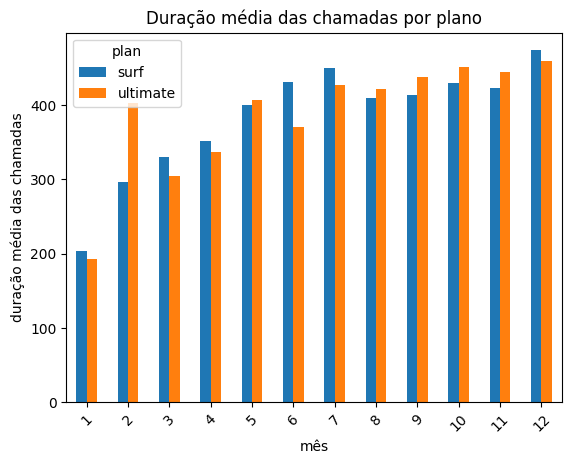

In [31]:

# Compare a duração média das chamadas de cada plano para cada mês. Crie um gráfico de barras para visualizar o resultado.

calls_pivot = user_usage_with_plan.pivot_table(index='month', columns='plan', values='duration_rounded', aggfunc='mean')


calls_pivot.plot(kind='bar',title='Duração média das chamadas por plano',xlabel='mês',ylabel='duração média das chamadas',rot=45)
plt.show()

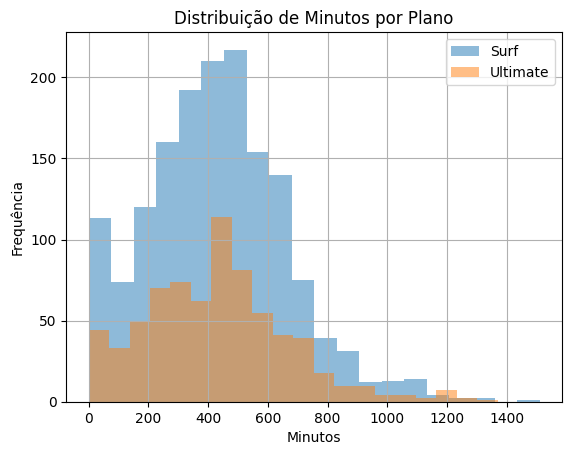

In [32]:

# Histograma do plano Surf
user_usage_with_plan[user_usage_with_plan['plan'] == 'surf']['duration_rounded'].hist(alpha=0.5, bins=20, label='Surf')
# Histograma do plano Ultimate
user_usage_with_plan[user_usage_with_plan['plan'] == 'ultimate']['duration_rounded'].hist(alpha=0.5, bins=20, label='Ultimate')

plt.title('Distribuição de Minutos por Plano')
plt.xlabel('Minutos')
plt.ylabel('Frequência')
plt.legend()
plt.show()

In [33]:

# Calcule a média e a variância da duração mensal das chamadas
calls_stats = user_usage_with_plan.groupby('plan')['duration_rounded'].agg(['mean', 'var', 'std'])

display("Estatísticas da Duração das Chamadas:", calls_stats)

'Estatísticas da Duração das Chamadas:'

,mean,var,std
plan,,,
surf,428.749523,54968.279461,234.453150
ultimate,430.450000,57844.464812,240.508762


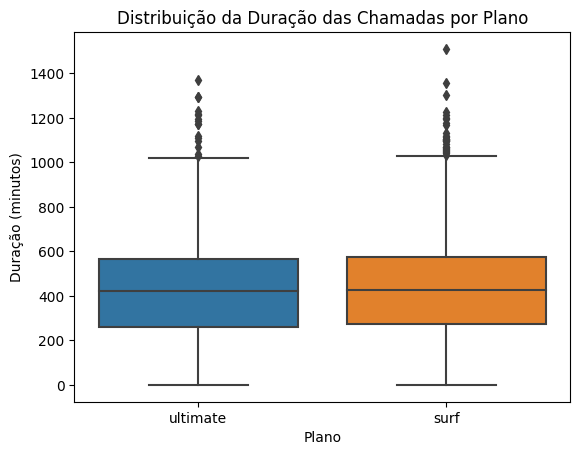

In [34]:

# Faça um diagrama de caixa para visualizar a distribuição da duração mensal das chamadas
sns.boxplot(data=user_usage_with_plan, x='plan', y='duration_rounded')

plt.title('Distribuição da Duração das Chamadas por Plano')
plt.xlabel('Plano')
plt.ylabel('Duração (minutos)')
plt.show()


A duração média mensal das chamadas é quase idêntica entre os dois planos (~429 min no Surf vs ~430 min no Ultimate). Isto confirma que o perfil de consumo de voz não depende do plano contratado: os clientes falam o que necessitam, independentemente de terem um limite de 500 ou 3000 minutos.

Ambos os planos apresentam uma variância e desvio padrão elevados. Isto indica que, em ambos os grupos, existe uma grande dispersão: temos desde utilizadores que quase não fazem chamadas e utilizadores que ultrapassam largamente as médias.

Embora a média do Surf (429 min) esteja abaixo do limite de 500 minutos, o desvio padrão elevado indica que uma parte significativa dos clientes ultrapassa frequentemente essa barreira, gerando receitas adicionais por minutos excedentes.

Os utilizadores do plano Ultimate utilizam, em média, apenas 14% da sua franquia de 3000 minutos. Para a operadora, este plano funciona como uma receita fixa alta com um custo de rede muito previsível e baixo risco de sobrecarga.

### Mensagens

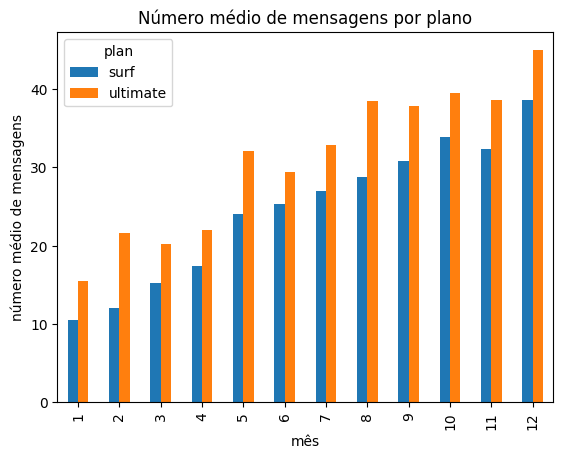

In [35]:

# Compare o número de mensagens que os usuários de cada plano costumam enviar a cada mês
messages_pivot = user_usage_with_plan.pivot_table(index='month', columns='plan', values='id_y', aggfunc='mean')

messages_pivot.plot(kind='bar',title='Número médio de mensagens por plano',xlabel='mês',ylabel='número médio de mensagens')

plt.show()

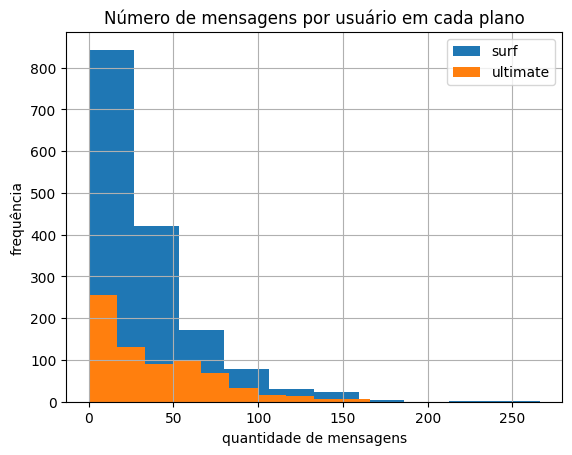

In [36]:


# Comparação o número de mensagens que os usuários de cada plano necessitam a cada mês. 
user_usage_with_plan[user_usage_with_plan['plan']=='surf']['id_y'].hist()
user_usage_with_plan[user_usage_with_plan['plan']=='ultimate']['id_y'].hist()

plt.title('Número de mensagens por usuário em cada plano')
plt.xlabel('quantidade de mensagens')
plt.ylabel('frequência')
plt.legend(['surf','ultimate'])
plt.show()


In [37]:


# Calculo da média e variância do número mensal de mensagens
messages_stats = user_usage_with_plan.groupby('plan')['id_y'].agg(['mean', 'var', 'std'])

display("Estatísticas do Número de Mensagens:", messages_stats)

'Estatísticas do Número de Mensagens:'

,mean,var,std
plan,,,
surf,31.159568,1126.724522,33.566717
ultimate,37.551389,1208.756744,34.767179


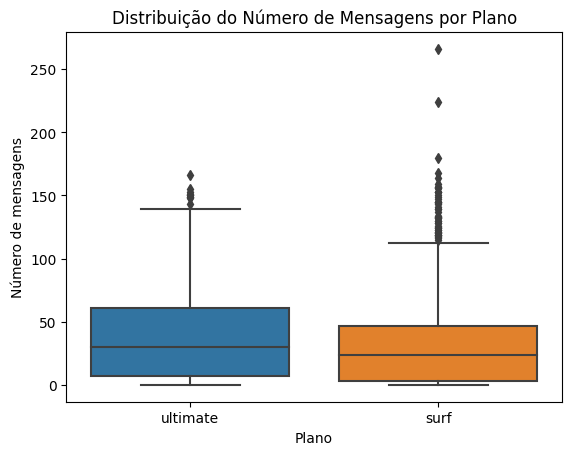

In [38]:

# Diagrama de caixa para visualizar a distribuição do número de mensagens
sns.boxplot(data=user_usage_with_plan, x='plan', y='id_y')

plt.title('Distribuição do Número de Mensagens por Plano')
plt.xlabel('Plano')
plt.ylabel('Número de mensagens')
plt.show()


Existe uma diferença no volume médio de mensagens: os utilizadores do plano Ultimate enviam, em média, cerca de 20% mais mensagens (37.55) do que os do plano Surf (31.16). Embora o uso seja maior no Ultimate, a média continua drasticamente longe do limite de 1000 SMS, o que reforça que este serviço é subutilizado mesmo quando "ilimitado".

Ambos os planos apresentam um desvio padrão de aproximadamente 34, que, no caso do Surf, é superior à própria média. Isto confirma uma distribuição fortemente assimétrica à direita: a grande maioria dos clientes envia pouquíssimas ou nenhuma mensagem (pico no zero), enquanto uma pequena minoria de utilizadores intensivos é responsável por elevar a média global.

Com uma média de 31 mensagens e um desvio padrão de 33, torna-se evidente que, embora o utilizador "típico" esteja dentro do limite de 50 SMS, há uma fatia considerável de clientes que ultrapassa essa barreira regularmente, contribuindo para a receita de excedentes da operadora.

O facto de as médias serem baixas em ambos os planos, mesmo no Ultimate onde não há pressão de custo, sugere que as mensagens foram amplamente substituídas por outras formas de comunicação (como apps de mensagens instantâneas), sendo utilizado apenas de forma residual pela maioria da base de clientes.

### Internet

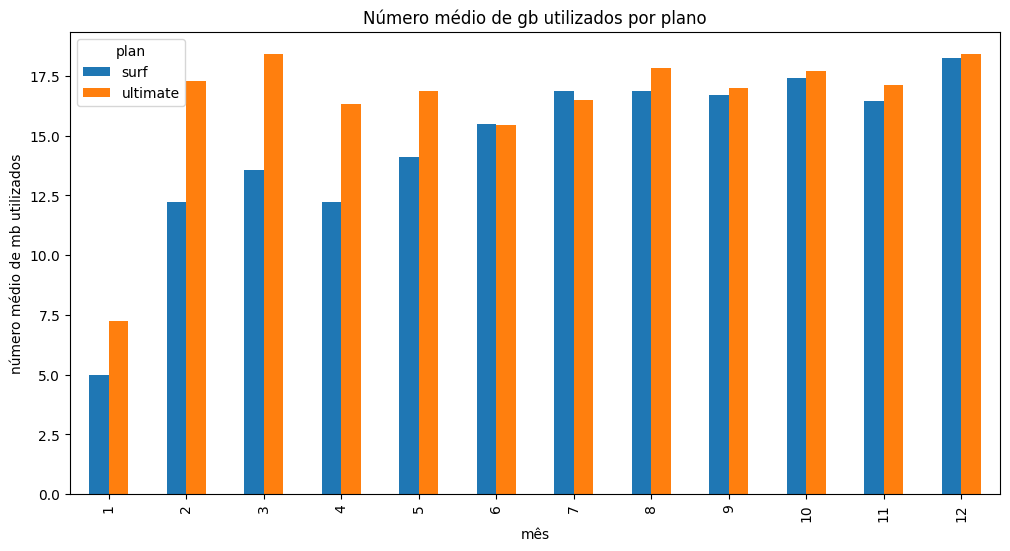

In [39]:

# Compare o tráfego utilizado pelos usuários de cada plano a cada mês
internet_pivot = user_usage_with_plan.pivot_table(index='month', columns='plan', values='gb_used', aggfunc='mean')

internet_pivot.plot(kind='bar',title='Número médio de gb utilizados por plano',xlabel='mês',ylabel='número médio de mb utilizados',figsize=(12,6))

plt.show()

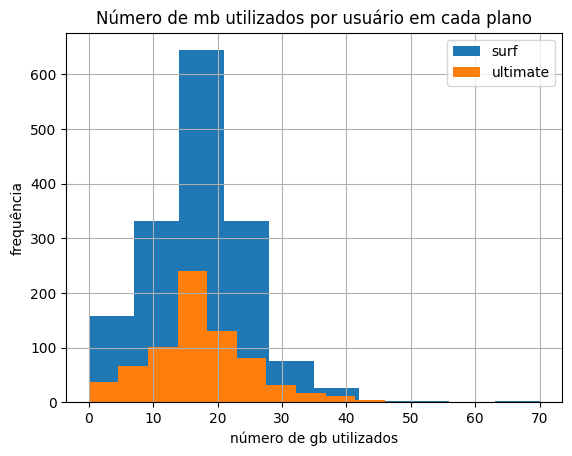

In [40]:

# Comparação do número de mb que os usuários de cada plano necessitam a cada mês. 
user_usage_with_plan[user_usage_with_plan['plan']=='surf']['gb_used'].hist()
user_usage_with_plan[user_usage_with_plan['plan']=='ultimate']['gb_used'].hist()

plt.title('Número de mb utilizados por usuário em cada plano')
plt.xlabel('número de gb utilizados')
plt.ylabel('frequência')
plt.legend(['surf','ultimate'])
plt.show()

In [41]:

# Calculo da média e variância do número mb utilizados
internet_stats = user_usage_with_plan.groupby('plan')['gb_used'].agg(['mean', 'var', 'std'])

display("Estatísticas do Número de MB utilizados:", internet_stats)

'Estatísticas do Número de MB utilizados:'

,mean,var,std
plan,,,
surf,16.670693,61.58360,7.847522
ultimate,17.306944,58.83055,7.670108


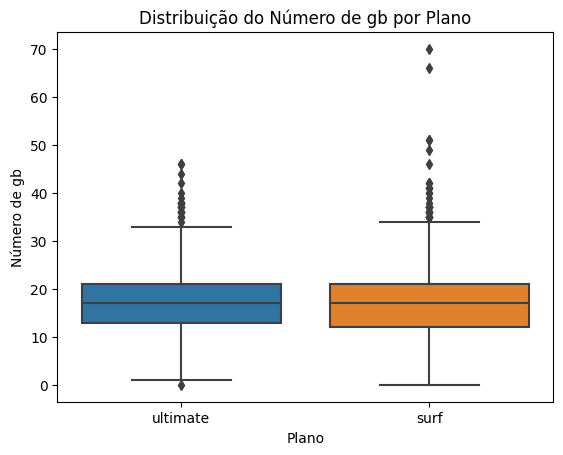

In [42]:

# Diagrama de caixa para visualizar a distribuição do número de mb utilizados
sns.boxplot(data=user_usage_with_plan, x='plan', y='gb_used')

plt.title('Distribuição do Número de gb por Plano')
plt.xlabel('Plano')
plt.ylabel('Número de gb')
plt.show()


O diagrama de caixa confirma que a mediana e a média (~16.7 GB) do plano Surf estão acima do limite de 15 GB. Isso significa que mais de metade dos utilizadores deste plano gera receita extra para a operadora através de dados excedentes.

No plano Ultimate, a "caixa" (que representa 50% dos utilizadores) situa-se bem abaixo da linha dos 30 GB. Mesmo os utilizadores na parte superior da distribuição raramente atingem o limite do plano, evidenciando que os clientes pagam um valor premium para não terem limites, mas não pela necessidade real de consumo.

A amplitude das caixas e dos "bigodes" é muito semelhante entre os dois planos, o que reforça a ideia de que o comportamento digital é um traço do utilizador moderno e não um reflexo das barreiras do tarifário. A variância alta (~60) indica que a operadora lida com perfis muito heterogéneos em ambos os segmentos.

## Receita

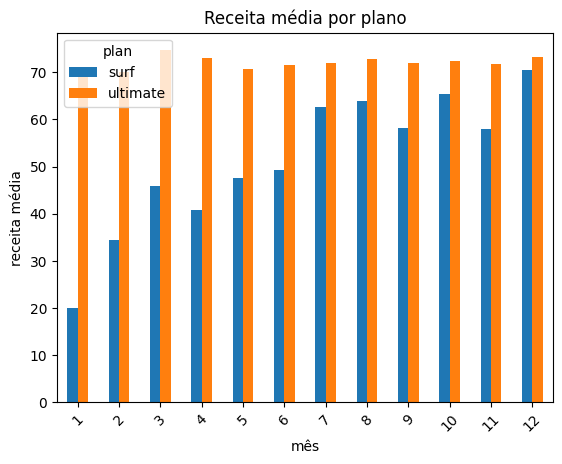

In [43]:

# Comparação da receita média de cada plano para cada mês. Gráfico de barras para visualizar o resultado.

calls_pivot = user_usage_with_plan.pivot_table(index='month', columns='plan', values='revenue', aggfunc='mean')


calls_pivot.plot(kind='bar',title='Receita média por plano',xlabel='mês',ylabel='receita média',rot=45)
plt.show()

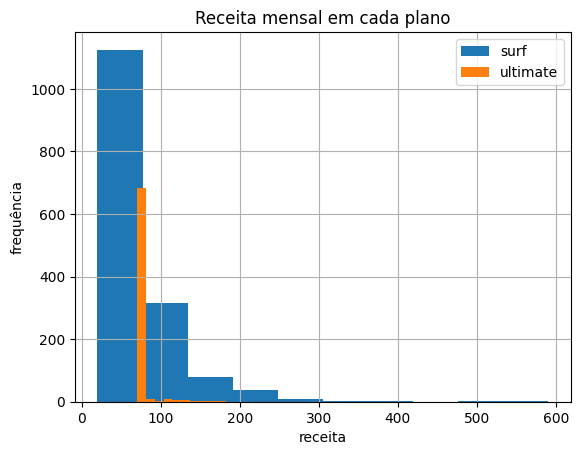

In [44]:

# Comparação da receita de cada plano por mês. 
user_usage_with_plan[user_usage_with_plan['plan']=='surf']['revenue'].hist()
user_usage_with_plan[user_usage_with_plan['plan']=='ultimate']['revenue'].hist()

plt.title('Receita mensal em cada plano')
plt.xlabel('receita')
plt.ylabel('frequência')
plt.legend(['surf','ultimate'])
plt.show()

In [45]:

# Calculo da média e variância da receita mensal
revenue_stats = user_usage_with_plan.groupby('plan')['revenue'].agg(['mean', 'var', 'std'])

display("Estatísticas da receita mensal:", revenue_stats)

'Estatísticas da receita mensal:'

,mean,var,std
plan,,,
surf,60.706408,3067.835152,55.388042
ultimate,72.313889,129.848486,11.395108


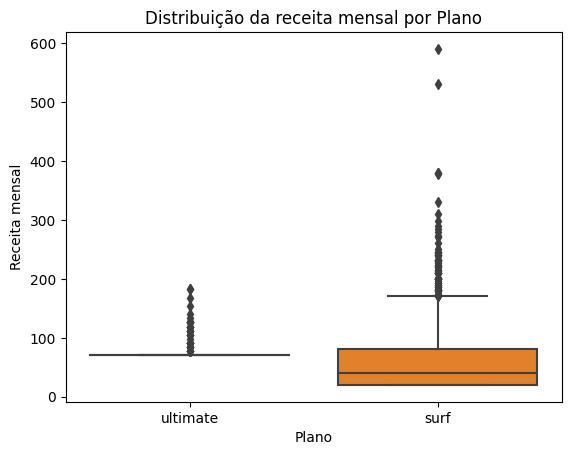

In [46]:

#Diagrama de caixa para visualizar a distribuição da receita mensal por plano
sns.boxplot(data=user_usage_with_plan, x='plan', y='revenue')

plt.title('Distribuição da receita mensal por Plano')
plt.xlabel('Plano')
plt.ylabel('Receita mensal')
plt.show()


A receita média do plano Ultimate (72.31) é superior à do plano Surf (60.71). No entanto, é de salientar que, embora o custo base do Surf seja de apenas $20, o utilizador médio acaba por pagar mais do triplo desse valor devido aos consumos excedentes, aproximando-se da receita gerada pelo plano premium.

O plano Surf apresenta uma variância altíssima (3067.84), o que indica uma enorme dispersão. No boxplot, isto reflete-se numa "caixa" alongada e muitos valores atípicos que chegam a ultrapassar os $200. Isto mostra que o lucro no Surf é imprevisível e depende fortemente do excesso de uso de dados.

O plano Ultimate tem uma variância muito baixa (129.85), confirmando que a receita é estável e previsível. A maioria esmagadora dos clientes paga apenas a mensalidade fixa.

No Surf, a mediana está muito abaixo da média, o que confirma uma distribuição assimétrica à direita (muitas pessoas pagam pouco, mas algumas pagam muito, puxando a média para cima).

No Ultimate, o boxplot aparece "esmagado" em torno dos $70, pois não há variabilidade quase nenhuma; o plano funciona como um modelo de subscrição.

Para a Megaline, o plano Surf é altamente lucrativo por "penalizar" o consumo extra, enquanto o Ultimate é lucrativo pela "subutilização" (o cliente paga por 30GB mas consome, em média, apenas 17GB).

## Teste hipóteses estatísticas


Hipótese nula: A receita média dos usuários dos plaos Surf e Ultimate é igual
Hipótese alternativa: A receita média doss usuários dos plaos Surf e Ultimate é diferente

Teste escolhido: teste t de Student bilateral

In [47]:

# Teste as hipóteses

revenue_surf = user_usage_with_plan[user_usage_with_plan['plan']=='surf']['revenue']
revenue_ultimate = user_usage_with_plan[user_usage_with_plan['plan']=='ultimate']['revenue']
alpha = 0.05

var_surf = revenue_surf.var()
var_ultimate = revenue_ultimate.var()
print(f"Variância Surf: {var_surf}")
print(f"Variância Ultimate: {var_ultimate}")

if var_surf == var_ultimate:
    variancias_iguais = True
else:
    variancias_iguais = False

results_1 = st.ttest_ind(revenue_surf,revenue_ultimate,equal_var=variancias_iguais)
print('valor-p:', results_1.pvalue)

if results_1.pvalue < alpha:
    print('Rejeitamos a hipótese nula')
else:
    print('Não podemos rejeitar a hipótese nula')


Variância Surf: 3067.835152293878
Variância Ultimate: 129.8484855509195
valor-p: 3.1703905481135734e-15
Rejeitamos a hipótese nula


<div class="alert alert-block alert-danger">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

Precisamos seguir estes passos para o teste de hipótese:
- Avaliar se as variâncias são iguais, por exemplo, calculando a variância da amostra e verificando a igualdade (ex: sample1.var() == sample2.var())
- Em seguida, ajustar equal_var=True no teste T se as variâncias forem iguais, senão usamos equal_var=False no teste T: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html.
- Avaliar o resultado do teste T

Note que você configurou equal_var=False mas não avaliou as variâncias.
</div>


<div class="alert alert-block alert-success">
<b> Comentário do revisor v2: </b> <a class="tocSkip"></a>

correto. podemos também usar o teste Levene para avaliar igualdade entre variâncias
</div>


O valor-p é inferior ao nível de significância de 0.05.
Rejeitamos a hipótese nula. 

Existe evidência estatística de que os utilizadores do plano Surf têm um comportamento diferente dos utilizadores do plano Ultimate.

Embora o plano Ultimate tenha uma média absoluta maior (72.31), o plano Surf é um gerador de receita dinâmico, onde os utilizadores frequentemente excedem os limites e pagam taxas adicionais, elevando a média para muito acima do custo base de $20.2.


Hipótese nula: A receita média dos usuários de NY-NJ é igual à dos usuários das demais regiões
Hipótes alternativa: A receita média dos usuários de NY-NJ é diferente da dos usuários das demais regiões

Teste escolhido: teste t de Student bilateral

In [48]:

# Teste as hipóteses
revenue_ny_nj = user_usage_with_plan[user_usage_with_plan['is_ny_nj']==True]['revenue']
revenue_other_city = user_usage_with_plan[user_usage_with_plan['is_ny_nj']==False]['revenue']
alpha = 0.05

var_ny_nj = revenue_ny_nj.var()
var_other_city = revenue_other_city.var()
print("Variância NY-NJ:", revenue_ny_nj.var())
print("Variância Outras Cidades:", revenue_other_city.var())

if var_ny_nj == var_other_city:
    variancias_iguais2 = True
else:
    variancias_iguais2 = False

results_2 = st.ttest_ind(revenue_ny_nj,revenue_other_city,equal_var=variancias_iguais2)
print('valor-p:', results_2.pvalue)

if results_2.pvalue < alpha:
    print('Rejeitamos a hipótese nula')
else:
    print('Não podemos rejeitar a hipótese nula')


Variância NY-NJ: 1895.5456899204246
Variância Outras Cidades: 2225.0479943518917
valor-p: 0.0335256158853001
Rejeitamos a hipótese nula


<div class="alert alert-block alert-danger">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

Precisamos seguir estes passos para o teste de hipótese:
- Avaliar se as variâncias são iguais, por exemplo, calculando a variância da amostra e verificando a igualdade (ex: sample1.var() == sample2.var())
- Em seguida, ajustar equal_var=True no teste T se as variâncias forem iguais, senão usamos equal_var=False no teste T: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html.
- Avaliar o resultado do teste T

Note que você configurou equal_var=False mas não avaliou as variâncias.
</div>


<div class="alert alert-block alert-success">
<b> Comentário do revisor v2: </b> <a class="tocSkip"></a>

correto
</div>

O valor-p é inferior ao nível de significância de 0.05.
Rejeitamos a hipótese nula. 

Existe evidência estatística de que os utilizadores da área metropolitana de Nova Iorque e Nova Jérsia têm um comportamento de faturação diferente do resto do país.

Isto sugere que fatores regionais (como densidade populacional, custo de vida ou disponibilidade de redes Wi-Fi) podem estar a influenciar o consumo de dados e chamadas nesta região específica, justificando uma atenção estratégica diferenciada para este mercado.

## Conclusão geral

Durante a análise, identificámos valores ausentes nas comunicações (chamadas, SMS e dados). Estes foram preenchidos com 0, assumindo que a ausência de registo representava a não utilização do serviço naquele mês, o que permitiu uma análise de receita mais precisa.

Seguindo as políticas da Megaline, os minutos foram arredondados para cima antes da soma mensal e o tráfego de internet foi convertido para gb e arredondado para cima ao fim do mês para o cálculo da faturação.

Consolidámos as tabelas de utilizadores, chamadas, mensagens e internet numa única base de dados mensal por utilizador, garantindo que nenhum dado de consumo fosse perdido na análise de receita.

Surpreendentemente, os utilizadores de ambos os planos consomem uma quantidade quase idêntica de minutos (~430 min), sugerindo que a necessidade de comunicação de voz é independente do tarifário.

Os utilizadores do plano Ultimate utilizam apenas uma pequena fração dos seus limites (14% dos minutos e 58% dos dados). Este plano funciona como uma garantia de receita fixa elevada para a operadora sem sobrecarregar a rede.

No plano Surf, a média de consumo de internet (16.67 gb) excede o limite do plano (15 gb). A internet é o principal serviço que leva os utilizadores deste plano a pagarem taxas excedentes.

Estatísticas da receita por plano: Rejeitámos a hipótese nula com um valor-p extremamente baixo, confirmando que o plano Ultimate gera, em média, mais receita por cliente do que o plano Surf. No entanto, a alta variabilidade do Surf mostra que este plano é capaz de gerar receitas individuais muito elevadas através de extras.

Estatísticas da receita por geografia: Rejeitámos a hipótese nula, concluindo que os utilizadores da área de NY-NJ têm um comportamento de gasto diferente das restantes regiões. Isto indica que este mercardo tem particularidades que podem exigir estratégias de marketing específicas.

Para maximizar a receita, a Megaline deve:
1. Focar o orçamento de publicidade no plano Ultimate, pois ele garante uma margem de lucro maior e mais estável, com baixo risco de custos operacionais (já que os clientes raramente usam todo o plafond).
2. Monitorizar os utilizadores "extremos" do plano Surf: Como muitos pagam regularmente por gb extras, existe uma oportunidade de tentar migrá-los para o Ultimate, aumentando a fidelização e a previsibilidade da receita.
3. Explorar o mercado NY-NJ: dada a diferença estatística encontrada, recomenda-se uma análise qualitativa para entender se nesta região a procura por pacotes de dados é maior, permitindo talvez o lançamento de um plano intermédio.